# 02 - Data quality

**Question:** Can the exported tables be trusted, and what handling rules do the metrics rely on?

Each check ends in **PASS**, **REVIEW** or **FAIL**. Decisions are recorded at the end and copied into `data/data_dictionary.md`.

In [1]:
# --- Setup: run this cell first ---
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "productpulse").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from productpulse import data, metrics, charts

charts.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(data.data_banner())

Real BigQuery export loaded from: C:\Users\Padmashree\OneDrive\Desktop\ProductPulse-AI\ProductPulse-AI\data\exports


In [2]:
overview = data.load("dataset_overview")
quality = data.load("data_quality")
daily = data.load("daily_metrics")
tx = data.load("transactions")
funnel_sql = data.load("user_funnel_by_device")
fact, dim = data.load_model()

results = []   # (check, status, detail)
def record(check, ok, detail, review=False):
    status = "PASS" if ok else ("REVIEW" if review else "FAIL")
    results.append((check, status, detail))
    print(f"[{status:^6}] {check}: {detail}")

## 1. Checks computed in SQL\nThese counts come straight from BigQuery (`sql/exports/data_quality.sql`, same logic as Q07-Q11).

In [3]:
q = quality.set_index("check_name")["value"]
display(quality.style.format({"value": "{:,.2f}"}))

rows = q["event_rows"]
record("Null user ids", q["null_user_id_rows"] == 0,
       f"{q['null_user_id_rows']:,.0f} rows ({q['null_user_id_rows'] / rows:.3%}) - excluded from user metrics", review=True)
record("Null session ids", q["null_session_id_rows"] == 0,
       f"{q['null_session_id_rows']:,.0f} rows ({q['null_session_id_rows'] / rows:.3%}) - excluded from session metrics", review=True)
record("Exact duplicate events", q["duplicate_extra_copies"] == 0,
       f"{q['duplicate_extra_copies']:,.0f} extra copies ({q['duplicate_extra_copies'] / rows:.3%}) - reported, not removed", review=True)
record("Purchases without a usable transaction id", q["purchase_null_or_not_set_transaction_id"] == 0,
       f"{q['purchase_null_or_not_set_transaction_id']:,.0f} of {q['purchase_events']:,.0f} purchase events - excluded from validated orders", review=True)
gap = q["revenue_summing_every_event_usd"] - q["revenue_deduplicated_usd"]
record("Revenue double counting risk", abs(gap) < 0.005,
       f"summing every purchase event gives ${gap:,.2f} more than de-duplicated revenue", review=True)

,check_name,value,note
0,revenue_deduplicated_usd,"308,200.00",Used everywhere in this project
1,not_set_country_rows,"32,208.00",Shown as (not set)
2,purchase_null_revenue,0.00,Treated as 0 revenue
3,null_user_id_rows,0.00,Excluded from user metrics
4,orders_with_repeat_purchase_events,326.00,Reason revenue is de-duplicated
5,revenue_summing_every_event_usd,"362,165.00",NOT used: may double count
6,purchase_events,"5,692.00",Rows with event_name = purchase
7,validated_orders,"4,451.00",Distinct valid transaction_id
8,null_device_rows,0.00,Shown as (not set)
9,data_deleted_source_rows,"308,695.00",Obfuscation artefact; channel = Data deleted


[ PASS ] Null user ids: 0 rows (0.000%) - excluded from user metrics
[ PASS ] Null session ids: 0 rows (0.000%) - excluded from session metrics
[ PASS ] Exact duplicate events: 0 extra copies (0.000%) - reported, not removed
[REVIEW] Purchases without a usable transaction id: 906 of 5,692 purchase events - excluded from validated orders
[REVIEW] Revenue double counting risk: summing every purchase event gives $53,965.00 more than de-duplicated revenue


## 2. Keys and joins\nThe model is a small star: `dim_user` (one row per user) to `fact_user_day` (one row per user per day).

In [4]:
record("dim_user is unique per user", dim["user_pseudo_id"].is_unique,
       f"{dim['user_pseudo_id'].duplicated().sum():,} duplicate user ids")
dup_fact = fact.duplicated(["user_pseudo_id", "event_dt"]).sum()
record("fact_user_day is unique per user-day", dup_fact == 0, f"{dup_fact:,} duplicate user-day rows")
orphans = ~fact["user_pseudo_id"].isin(dim["user_pseudo_id"])
record("Every fact row has a user in dim_user", orphans.sum() == 0, f"{orphans.sum():,} orphan rows")
record("User count matches the SQL overview",
       dim["user_pseudo_id"].nunique() == int(overview["identified_users"].iloc[0]),
       f"dim_user {dim['user_pseudo_id'].nunique():,} vs SQL {int(overview['identified_users'].iloc[0]):,}")
record("No missing values in the fact table", fact.isna().sum().sum() == 0,
       f"{int(fact.isna().sum().sum()):,} missing cells")

[ PASS ] dim_user is unique per user: 0 duplicate user ids
[ PASS ] fact_user_day is unique per user-day: 0 duplicate user-day rows
[ PASS ] Every fact row has a user in dim_user: 0 orphan rows
[ PASS ] User count matches the SQL overview: dim_user 270,154 vs SQL 270,154
[ PASS ] No missing values in the fact table: 0 missing cells


## 3. Dates

In [5]:
start, end = overview["first_event_date"].iloc[0], overview["last_event_date"].iloc[0]
outside = ((fact["event_dt"] < start) | (fact["event_dt"] > end)).sum()
record("All fact dates are inside the sample period", outside == 0,
       f"{outside:,} rows outside {start.date()} to {end.date()}")
record("first_seen_dt <= last_seen_dt", (dim["first_seen_dt"] <= dim["last_seen_dt"]).all(),
       f"{(dim['first_seen_dt'] > dim['last_seen_dt']).sum():,} users violate this")
first_in_fact = fact.groupby("user_pseudo_id")["event_dt"].min()
mismatch = (first_in_fact.reindex(dim["user_pseudo_id"]).values != dim["first_seen_dt"].values).sum()
record("first_seen_dt equals the first fact date", mismatch == 0, f"{mismatch:,} users differ")
record("cohort_month is the month of first_seen_dt",
       (dim["cohort_month"] == dim["first_seen_dt"].dt.to_period("M").dt.to_timestamp()).all(), "checked for all users")
utc = q.get("utc_date_differs_rows", np.nan)
print(f"Info: {utc:,.0f} rows ({utc / rows:.2%}) have a UTC date different from event_date. "
      "Expected: event_date uses the property's time zone, event_timestamp is UTC.")

[ PASS ] All fact dates are inside the sample period: 0 rows outside 2020-11-01 to 2021-01-31
[ PASS ] first_seen_dt <= last_seen_dt: 0 users violate this
[ PASS ] first_seen_dt equals the first fact date: 0 users differ
[ PASS ] cohort_month is the month of first_seen_dt: checked for all users
Info: 0 rows (0.00%) have a UTC date different from event_date. Expected: event_date uses the property's time zone, event_timestamp is UTC.


## 4. Category values

In [6]:
expected_devices = {"desktop", "mobile", "tablet"}
found = set(dim["device_category"].unique())
record("Device categories are the expected set", found <= expected_devices,
       f"found {sorted(found)}", review=True)

for column in ["device_category", "channel_group"]:
    share = dim[column].value_counts(normalize=True).rename("share_of_users").to_frame()
    share["users"] = dim[column].value_counts()
    display(share.style.format({"share_of_users": "{:.1%}", "users": "{:,.0f}"}))

not_set_country = (dim["country"] == "(not set)").mean()
record("Country is populated", not_set_country < 0.02, f"{not_set_country:.2%} of users have country '(not set)'", review=True)
multi_device = (dim["n_devices"] > 1).mean()
record("Users seen on more than one device", multi_device < 0.02,
       f"{multi_device:.2%} of users - they are assigned their FIRST device", review=True)

[ PASS ] Device categories are the expected set: found ['desktop', 'mobile', 'tablet']


,share_of_users,users
device_category,,
desktop,58.1%,"156,905"
mobile,39.7%,"107,175"
tablet,2.2%,"6,074"


,share_of_users,users
channel_group,,
Organic search,37.7%,"101,742"
Direct,23.7%,"64,109"
Other,17.4%,"47,101"
Referral,14.8%,"40,019"
Paid search,5.3%,"14,282"
Data deleted,1.1%,"2,901"


[ PASS ] Country is populated: 0.80% of users have country '(not set)'
[ PASS ] Users seen on more than one device: 1.55% of users - they are assigned their FIRST device


## 5. Transactions and revenue\nRule: an order is a distinct `transaction_id` that is not null and not `(not set)`. Revenue is counted once per order.

In [7]:
record("transaction_id is unique in the transactions table", tx["transaction_id"].is_unique,
       f"{tx['transaction_id'].duplicated().sum():,} duplicates")
repeat = (tx["purchase_events"] > 1).sum()
record("Orders recorded by more than one purchase event", repeat == 0,
       f"{repeat:,} of {len(tx):,} orders ({repeat / len(tx):.2%}) - this is why revenue is de-duplicated", review=True)
conflict = (tx["revenue_usd"].fillna(0) != tx["min_revenue_usd"].fillna(0)).sum()
record("Orders with conflicting revenue values", conflict == 0, f"{conflict:,} orders", review=True)
shared = (tx["distinct_users"] > 1).sum()
record("Orders shared by more than one user id", shared == 0, f"{shared:,} orders", review=True)
zero = (tx["revenue_usd"].fillna(0) <= 0).sum()
record("Orders with zero or missing revenue", zero == 0, f"{zero:,} orders ({zero / len(tx):.2%})", review=True)

record("Orders reconcile: fact vs transactions", int(fact["transactions"].sum()) == len(tx),
       f"fact {int(fact['transactions'].sum()):,} vs transactions {len(tx):,}")
record("Revenue reconciles: fact vs transactions",
       abs(fact["revenue_usd"].sum() - tx["revenue_usd"].sum()) < 0.01 * max(len(tx), 1),
       f"fact ${fact['revenue_usd'].sum():,.2f} vs transactions ${tx['revenue_usd'].sum():,.2f}")
record("Revenue reconciles: daily_metrics vs transactions",
       abs(daily["revenue_usd"].sum() - tx["revenue_usd"].sum()) < 0.01 * max(len(tx), 1),
       f"daily ${daily['revenue_usd'].sum():,.2f} vs transactions ${tx['revenue_usd'].sum():,.2f}")

[ PASS ] transaction_id is unique in the transactions table: 0 duplicates
[REVIEW] Orders recorded by more than one purchase event: 326 of 4,451 orders (7.32%) - this is why revenue is de-duplicated
[REVIEW] Orders with conflicting revenue values: 15 orders
[REVIEW] Orders shared by more than one user id: 15 orders
[ PASS ] Orders with zero or missing revenue: 0 orders (0.00%)
[ PASS ] Orders reconcile: fact vs transactions: fact 4,451 vs transactions 4,451
[ PASS ] Revenue reconciles: fact vs transactions: fact $308,200.00 vs transactions $308,200.00
[ PASS ] Revenue reconciles: daily_metrics vs transactions: daily $308,200.00 vs transactions $308,200.00


## 6. Outliers\nOutliers are flagged with the IQR rule (above Q3 + 3 x IQR). They are **kept**; the point is to know they exist and to prefer medians where they matter.

Order value: median $48.00, mean $69.24, max $1,530.00
[REVIEW] Extreme order values: 116 orders above $255.00


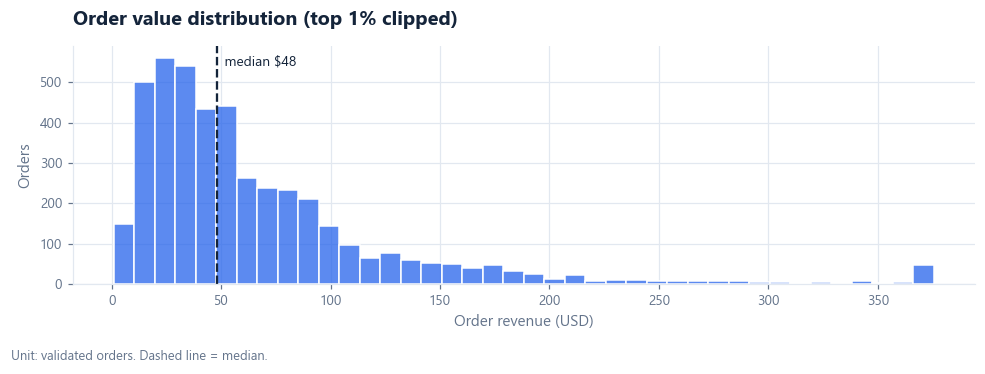

[REVIEW] Extreme user-days (possible bots or staff): 23,645 user-days above 32 events; top 0.1% starts at 304 events
The top 0.1% of user-days hold 2.65% of all events.


In [8]:
def iqr_outliers(series, k=3.0):
    q1, q3 = series.quantile([0.25, 0.75])
    limit = q3 + k * (q3 - q1)
    return limit, (series > limit).sum()

rev = tx["revenue_usd"].dropna()
limit, n_out = iqr_outliers(rev)
print(f"Order value: median ${rev.median():,.2f}, mean ${rev.mean():,.2f}, max ${rev.max():,.2f}")
record("Extreme order values", n_out == 0, f"{n_out:,} orders above ${limit:,.2f}", review=True)

fig, ax = plt.subplots(figsize=(9, 3.2))
sns.histplot(rev.clip(upper=rev.quantile(0.99)), bins=40, color=charts.BLUE, edgecolor="white", ax=ax)
ax.axvline(rev.median(), color=charts.NAVY, linewidth=1.5, linestyle="--")
ax.text(rev.median(), ax.get_ylim()[1] * 0.92, f"  median ${rev.median():,.0f}", color=charts.NAVY, fontsize=9)
ax.set_title("Order value distribution (top 1% clipped)")
ax.set_xlabel("Order revenue (USD)")
ax.set_ylabel("Orders")
charts.note(fig, "Unit: validated orders. Dashed line = median.")
plt.show()

events_day = fact["events"]
limit_e, n_out_e = iqr_outliers(events_day)
heavy = fact[fact["events"] > events_day.quantile(0.999)]
record("Extreme user-days (possible bots or staff)", n_out_e == 0,
       f"{n_out_e:,} user-days above {limit_e:,.0f} events; top 0.1% starts at {events_day.quantile(0.999):,.0f} events", review=True)
print(f"The top 0.1% of user-days hold {heavy['events'].sum() / fact['events'].sum():.2%} of all events.")

## 7. Quality report

In [9]:
report = pd.DataFrame(results, columns=["check", "status", "detail"])
display(report)
print(report["status"].value_counts().to_string())

out = data.ROOT / "reports" / ("data_quality_report.DEMO.csv" if data.get_data_dir()[1] else "data_quality_report.csv")
report.to_csv(out, index=False)
print("Saved:", out.relative_to(data.ROOT))
assert not (report["status"] == "FAIL").any(), "At least one check FAILED - fix the export before continuing."

,check,status,detail
0,Null user ids,PASS,0 rows (0.000%) - excluded from user metrics
1,Null session ids,PASS,0 rows (0.000%) - excluded from session metrics
2,Exact duplicate events,PASS,"0 extra copies (0.000%) - reported, not removed"
3,Purchases without a usable transaction id,REVIEW,"906 of 5,692 purchase events - excluded from v..."
4,Revenue double counting risk,REVIEW,"summing every purchase event gives $53,965.00 ..."
5,dim_user is unique per user,PASS,0 duplicate user ids
6,fact_user_day is unique per user-day,PASS,0 duplicate user-day rows
7,Every fact row has a user in dim_user,PASS,0 orphan rows
8,User count matches the SQL overview,PASS,"dim_user 270,154 vs SQL 270,154"
9,No missing values in the fact table,PASS,0 missing cells


status
PASS      20
REVIEW     7
Saved: reports\data_quality_report.csv


## Decisions (copy into `data/data_dictionary.md`)

| Issue | Decision | Effect on metrics |
|---|---|---|
| Null `user_pseudo_id` | Exclude the row from all user and session metrics | Distinct-user denominators are consistent everywhere |
| Null `ga_session_id` | Exclude from session metrics only | Session funnel covers slightly fewer events |
| Same-microsecond duplicate events | Keep, and report the count | User and session metrics use DISTINCT, so they are unaffected; raw event counts are slightly inflated |
| Purchase with null or `(not set)` transaction id | Not a validated order | Orders and revenue are slightly conservative |
| Repeated purchase events for one order | Count the order once, revenue once | Prevents double-counted revenue |
| Users on several devices or countries | Use the first observed value | Device and country splits are per user, not per event |
| `<Other>` and `(data deleted)` sources | Keep as their own channel groups | Channel comparisons disclose the obfuscated share |
| Extreme order values and user-days | Keep; use medians beside means | Averages can be pulled by a few rows |

**REVIEW** rows are expected in a real dataset. For each one, write the real count next to the decision above.